In [1]:
from google.colab import files
uploaded = files.upload()

Saving exp_2_dataset_student_scores.csv to exp_2_dataset_student_scores.csv


In [4]:
import pandas as pd

df = pd.read_csv("exp_2_dataset_student_scores.csv")

print("First 5 rows:\n", df.head(), "\n")
print("Last 5 rows:\n", df.tail(), "\n")
print("Developed by K.SriSaran Karthik")

First 5 rows:
    Hours  Scores
0    2.2      24
1    4.8      45
2    3.6      34
3    8.1      78
4    3.9      36 

Last 5 rows:
     Hours  Scores
20    3.0      33
21    5.0      52
22    4.1      40
23    6.7      74
24    8.0      88 

Developed by K.SriSaran Karthik


In [5]:
X = df.iloc[:, :-1].values
Y = df.iloc[:, -1].values

print("X (features):", X.flatten())
print("Y (targets):", Y)

X (features): [2.2 4.8 3.6 8.1 3.9 1.8 9.5 5.2 7.9 2.9 7.3 6.2 4.2 3.1 1.3 8.7 2.8 2.1
 6.4 7.1 3.  5.  4.1 6.7 8. ]
Y (targets): [24 45 34 78 36 22 91 57 79 28 82 65 43 39 18 93 32 26 70 73 33 52 40 74
 88]


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=1/3, random_state=0
)

print("\nTraining samples:", len(X_train), " Testing samples:", len(X_test))


Training samples: 16  Testing samples: 9


In [7]:
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train, Y_train)

LinearRegression()

In [8]:
import numpy as np

Y_pred = regressor.predict(X_test)

print("\nPredicted values:", np.round(Y_pred, 2))
print("Actual values   :", Y_test)


Predicted values: [20.87 38.45 72.62 30.64 63.83 43.33 23.8  81.4  68.71]
Actual values   : [22 34 73 32 65 40 26 88 74]


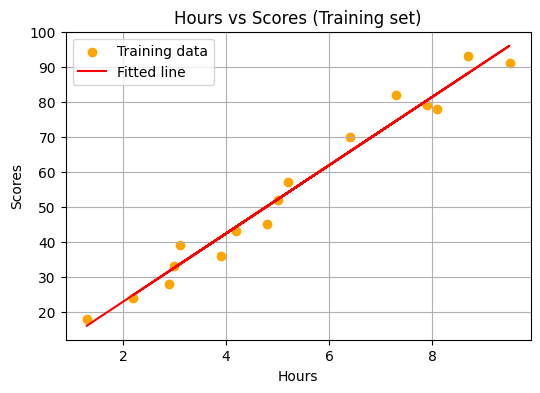

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.scatter(X_train, Y_train, color="orange", label="Training data")
plt.plot(X_train, regressor.predict(X_train), color="red", label="Fitted line")
plt.title("Hours vs Scores (Training set)")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.legend()
plt.grid(True)
plt.show()

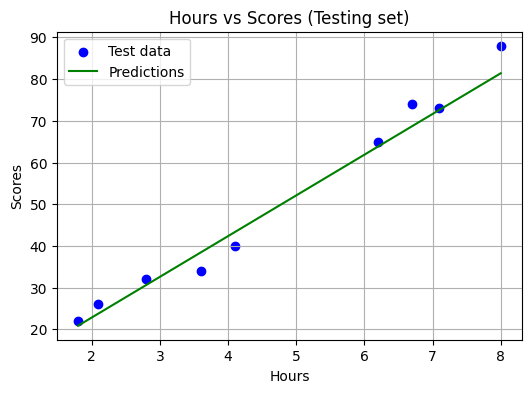

In [10]:
order = np.argsort(X_test.flatten())

X_test_sorted = X_test.flatten()[order]
Y_pred_sorted = Y_pred[order]

plt.figure(figsize=(6,4))
plt.scatter(X_test, Y_test, color="blue", label="Test data")
plt.plot(X_test_sorted, Y_pred_sorted, color="green", label="Predictions")
plt.title("Hours vs Scores (Testing set)")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)

print("\nMean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)


Mean Absolute Error (MAE): 2.878094152284161
Mean Squared Error (MSE): 12.426441774781104
Root Mean Squared Error (RMSE): 3.5251158526750728


In [12]:
new_hours = np.array([[2.5], [8.0]])

pred_new = regressor.predict(new_hours)

print("\nPredictions for new hours", new_hours.flatten(), "=>", np.round(pred_new, 2))


Predictions for new hours [2.5 8. ] => [27.71 81.4 ]
